# Customer Churn Prediction System — Deep Learning Pipeline

**Problem:** Predict whether a telecom customer will leave the service (binary classification).
**Dataset:** Telco Customer Churn (IBM / Kaggle) — 7,043 customers, 20 features.

| Requirement | Section |
|---|---|
| Data preprocessing | 2, 3 |
| Model design (ANN) | 4 |
| Regularization (L2, Dropout, BatchNorm, Early Stopping) | 5 |
| Hyperparameter tuning (Keras Tuner + manual) | 6 |
| Evaluation metrics | 7 |
| Model saving & loading | 8 |
| Deployment (prediction function + Streamlit app) | 9 |

## 0. Setup

In [1]:
# Run once (Colab already has TensorFlow; Keras Tuner usually needs installing)
!pip install -q keras-tuner

In [2]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks
import keras_tuner as kt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.utils.class_weight import compute_class_weight
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, roc_curve, precision_recall_curve,
                             ConfusionMatrixDisplay)
import joblib

SEED = 42
keras.utils.set_random_seed(SEED)   # sets Python, NumPy and TensorFlow seeds
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 1. Load Data & Exploratory Analysis

In [4]:
DATA_PATH = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
# TotalCharges is stored as text because some rows contain a blank space
print("Blank TotalCharges:", (df["TotalCharges"].str.strip() == "").sum())
print("Missing values:\n", df.isna().sum().sum())
print("\nChurn distribution:\n", df["Churn"].value_counts(normalize=True).round(3))

Blank TotalCharges: 11
Missing values:
 0

Churn distribution:
 Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


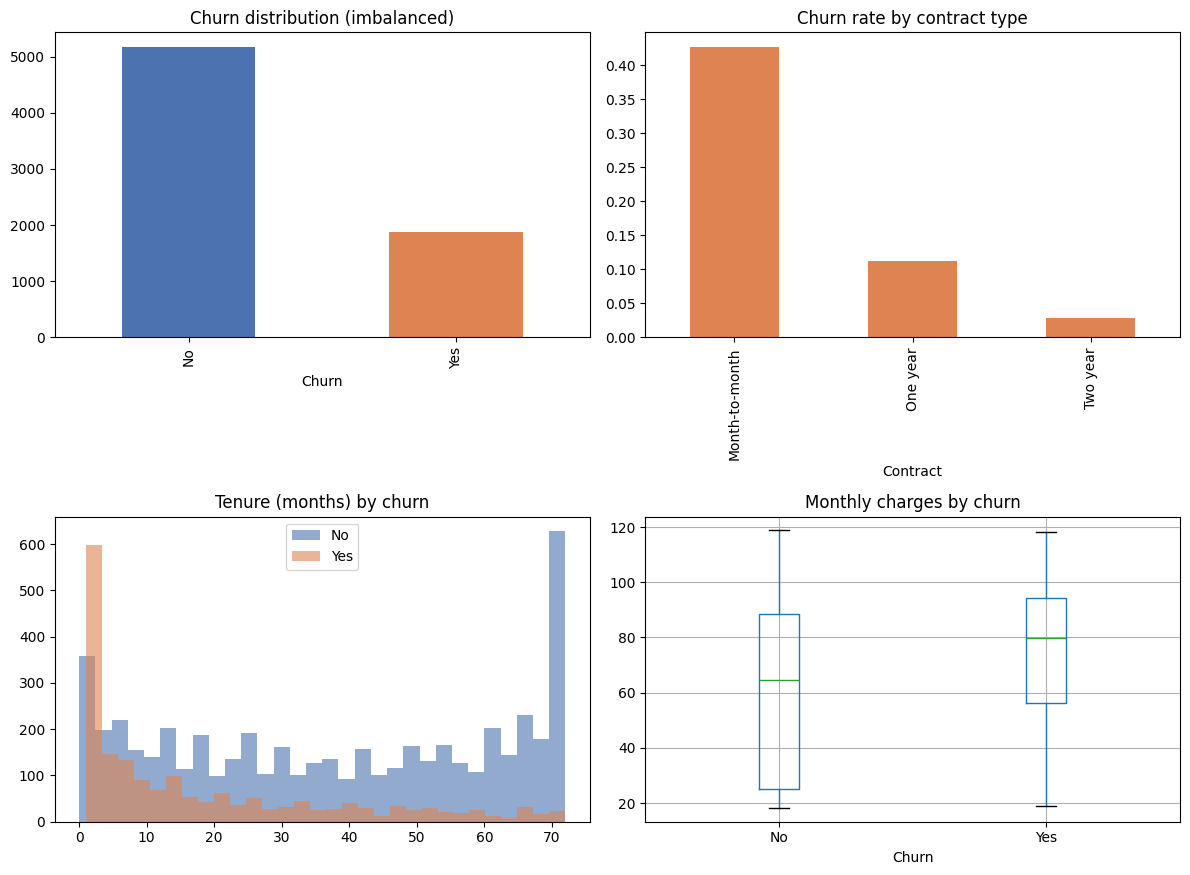

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

df["Churn"].value_counts().plot(kind="bar", ax=axes[0, 0], color=["#4C72B0", "#DD8452"])
axes[0, 0].set_title("Churn distribution (imbalanced)")

(df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean())
   .plot(kind="bar", ax=axes[0, 1], color="#DD8452"))
axes[0, 1].set_title("Churn rate by contract type")

for label, color in [("No", "#4C72B0"), ("Yes", "#DD8452")]:
    axes[1, 0].hist(df.loc[df["Churn"] == label, "tenure"], bins=30, alpha=0.6, label=label, color=color)
axes[1, 0].set_title("Tenure (months) by churn"); axes[1, 0].legend()

df.boxplot(column="MonthlyCharges", by="Churn", ax=axes[1, 1])
axes[1, 1].set_title("Monthly charges by churn")

plt.suptitle(""); plt.tight_layout(); plt.show()

**Observations:**
- About 26.5% of customers churn, so the classes are imbalanced. Accuracy alone is misleading, so we also track Recall, F1, ROC-AUC and PR-AUC.
- Month-to-month contracts, short tenure and high monthly charges are linked to churn.

## 2. Data Cleaning

In [8]:
df = df.drop(columns=["customerID"])                         # identifier, no predictive value

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Rows with missing TotalCharges:", df["TotalCharges"].isna().sum(),
      "| their tenure:", df.loc[df["TotalCharges"].isna(), "tenure"].unique())
# These are brand-new customers (tenure = 0) who have not been billed yet -> 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
df.shape

Rows with missing TotalCharges: 11 | their tenure: [0]


(7043, 20)

## 3. Preprocessing: Split, Encode, Scale

In [14]:
X = df.drop(columns=["Churn"])
y = df["Churn"].values

NUM_COLS = ["tenure", "MonthlyCharges", "TotalCharges"]
CAT_COLS = [c for c in X.columns if c not in NUM_COLS]

# 70% train / 15% validation / 15% test, stratified to keep the churn ratio
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)
print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), NUM_COLS),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
])

# Fit ONLY on training data to avoid data leakage
X_train_p = preprocessor.fit_transform(X_train).astype("float32")
X_val_p   = preprocessor.transform(X_val).astype("float32")
X_test_p  = preprocessor.transform(X_test).astype("float32")
INPUT_DIM = X_train_p.shape[1]
print("Features after encoding:", INPUT_DIM)

# Class weights to handle imbalance (churners get a higher weight)
weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
CLASS_WEIGHT = {0: weights[0], 1: weights[1]}
print("Class weights:", CLASS_WEIGHT)
CLASS_WEIGHT = None

Train: (4930, 19) Val: (1056, 19) Test: (1057, 19)
Features after encoding: 46
Class weights: {0: np.float64(0.680563224737714), 1: np.float64(1.8845565749235473)}


### 3.1 Reference model: Logistic Regression
A simple classical model, so we know whether the neural network adds value.

In [10]:
log_reg = LogisticRegression(max_iter=2000, class_weight="balanced")
log_reg.fit(X_train_p, y_train)
lr_test_prob = log_reg.predict_proba(X_test_p)[:, 1]
print("Logistic Regression test ROC-AUC:", round(roc_auc_score(y_test, lr_test_prob), 4))

Logistic Regression test ROC-AUC: 0.8448


## 4. Model Design: ANN for Binary Classification

In [11]:
def make_metrics():
    return [keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc")]

def build_ann(input_dim, units=(64, 32), dropout=0.0, l2=0.0, lr=1e-3, batchnorm=False):
    """Fully-connected ANN. Regularization is switched on through the arguments."""
    reg = regularizers.l2(l2) if l2 > 0 else None
    model = keras.Sequential([keras.Input(shape=(input_dim,))])
    for u in units:
        model.add(layers.Dense(u, kernel_regularizer=reg))
        if batchnorm:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))      # probability of churn
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="binary_crossentropy", metrics=make_metrics())
    return model

def plot_history(histories, metric="loss"):
    plt.figure(figsize=(6 * len(histories), 4))
    for i, (name, h) in enumerate(histories.items(), 1):
        plt.subplot(1, len(histories), i)
        plt.plot(h.history[metric], label="train")
        plt.plot(h.history["val_" + metric], label="validation")
        plt.title(f"{name} — {metric}"); plt.xlabel("Epoch"); plt.legend()
    plt.tight_layout(); plt.show()

### 4.1 Baseline ANN (no regularization)
A large network trained for many epochs with no regularization, to show overfitting.

In [12]:
baseline = build_ann(INPUT_DIM, units=(256, 128, 64))
baseline.summary()

start = time.time()
hist_base = baseline.fit(X_train_p, y_train, validation_data=(X_val_p, y_val),
                         epochs=100, batch_size=32, class_weight=CLASS_WEIGHT, verbose=0)
print(f"Training time: {time.time() - start:.1f}s")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        12,032 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,249 (208.00 KB)

 Trainable params: 53,249 (208.00 KB)

 Non-trainable params: 0 (0.00 B)

Training time: 66.4s


## 5. Regularization: L2 + Dropout + BatchNorm + Early Stopping

In [13]:
regularized = build_ann(INPUT_DIM, units=(256, 128, 64), dropout=0.3, l2=1e-3, batchnorm=True)

early_stop = callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=15,
                                     restore_best_weights=True, verbose=1)
reduce_lr = callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5,
                                        min_lr=1e-5, verbose=1)

start = time.time()
hist_reg = regularized.fit(X_train_p, y_train, validation_data=(X_val_p, y_val),
                           epochs=100, batch_size=32, class_weight=CLASS_WEIGHT,
                           callbacks=[early_stop, reduce_lr], verbose=0)
print(f"Stopped after {len(hist_reg.history['loss'])} epochs | time: {time.time() - start:.1f}s")

Epoch 22: early stopping
Restoring model weights from the end of the best epoch: 7.
Stopped after 22 epochs | time: 22.9s


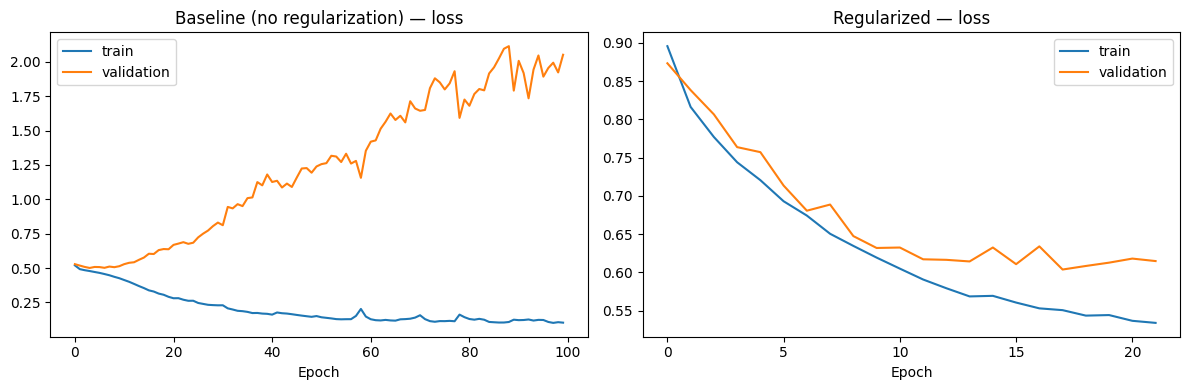

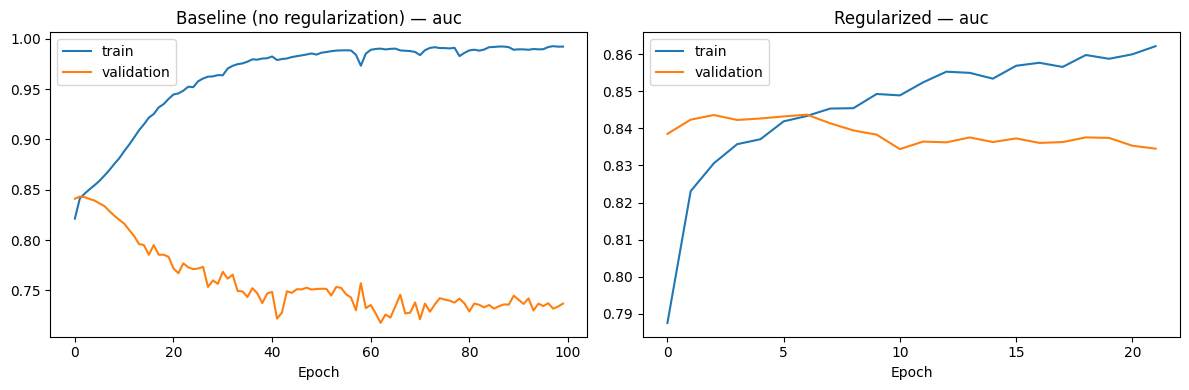

In [16]:
plot_history({"Baseline (no regularization)": hist_base, "Regularized": hist_reg}, "loss")
plot_history({"Baseline (no regularization)": hist_base, "Regularized": hist_reg}, "auc")

**Interpretation:** In the baseline, training loss keeps falling while validation loss rises after a few epochs. That gap is overfitting.
With L2, Dropout and BatchNorm the two curves stay close. Early Stopping ends training at the best validation AUC and restores those weights.

## 6. Hyperparameter Tuning

### 6.1 Keras Tuner (Random Search)

In [17]:
def tuner_model(hp):
    n_layers = hp.Int("n_layers", 1, 3)
    units = [hp.Choice(f"units_{i}", [16, 32, 64, 128, 256]) for i in range(n_layers)]
    return build_ann(
        INPUT_DIM,
        units=units,
        dropout=hp.Float("dropout", 0.0, 0.5, step=0.1),
        l2=hp.Choice("l2", [0.0, 1e-4, 1e-3, 1e-2]),
        lr=hp.Choice("lr", [3e-3, 1e-3, 5e-4, 1e-4]),
        batchnorm=hp.Boolean("batchnorm"),
    )

tuner = kt.BayesianOptimization(
    tuner_model,
    objective=kt.Objective("val_accuracy", direction="max"),
    max_trials=30,
    executions_per_trial=1,
    directory="tuner_dir",
    project_name="telco_churn",
    overwrite=True,
    seed=SEED,
)
tuner.search_space_summary()

Search space summary
Default search space size: 6
n_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Choice)
{'default': 16, 'conditions': [], 'values': [16, 32, 64, 128, 256], 'ordered': True}
dropout (Float)
{'default': 0.0, 'conditions': [], 'min_value': 0.0, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
l2 (Choice)
{'default': 0.0, 'conditions': [], 'values': [0.0, 0.0001, 0.001, 0.01], 'ordered': True}
lr (Choice)
{'default': 0.003, 'conditions': [], 'values': [0.003, 0.001, 0.0005, 0.0001], 'ordered': True}
batchnorm (Boolean)
{'default': False, 'conditions': []}


In [19]:
tuner.search(X_train_p, y_train,
             validation_data=(X_val_p, y_val),
             epochs=100, batch_size=32,
             class_weight=CLASS_WEIGHT,
             callbacks=[callbacks.EarlyStopping(monitor="val_accuracy", mode="max",
                                                patience=10, restore_best_weights=True)],
             verbose=1)

tuner.results_summary(num_trials=5)
best_hp = tuner.get_best_hyperparameters(1)[0]
print("\nBest hyperparameters:", best_hp.values)

Trial 30 Complete [00h 00m 13s]
val_accuracy: 0.8115530014038086

Best val_accuracy So Far: 0.8153409361839294
Total elapsed time: 00h 12m 43s
Results summary
Results in tuner_dir/telco_churn
Showing 5 best trials
Objective(name="val_accuracy", direction="max")

Trial 06 summary
Hyperparameters:
n_layers: 1
units_0: 128
dropout: 0.0
l2: 0.0001
lr: 0.003
batchnorm: False
units_1: 16
units_2: 64
Score: 0.8153409361839294

Trial 25 summary
Hyperparameters:
n_layers: 1
units_0: 64
dropout: 0.0
l2: 0.001
lr: 0.003
batchnorm: False
units_1: 32
units_2: 128
Score: 0.8125

Trial 29 summary
Hyperparameters:
n_layers: 2
units_0: 64
dropout: 0.0
l2: 0.001
lr: 0.003
batchnorm: False
units_1: 16
units_2: 32
Score: 0.8115530014038086

Trial 27 summary
Hyperparameters:
n_layers: 1
units_0: 32
dropout: 0.1
l2: 0.0001
lr: 0.003
batchnorm: False
units_1: 16
units_2: 32
Score: 0.810606062412262

Trial 09 summary
Hyperparameters:
n_layers: 1
units_0: 256
dropout: 0.4
l2: 0.0001
lr: 0.003
batchnorm: False


### 6.2 Manual tuning: batch size
Keras Tuner above tunes the architecture and regularization. Here we tune batch size by hand using the best settings.

In [20]:
batch_results = []
for bs in [16, 32, 64, 128]:
    keras.utils.set_random_seed(SEED)
    m = tuner.hypermodel.build(best_hp)
    t0 = time.time()
    h = m.fit(X_train_p, y_train, validation_data=(X_val_p, y_val),
              epochs=200, batch_size=bs, class_weight=CLASS_WEIGHT,
              callbacks=[callbacks.EarlyStopping(monitor="val_accuracy", mode="max",
                                                 patience=15, restore_best_weights=True)],
              verbose=0)
    batch_results.append({"batch_size": bs,
                          "best_val_accuracy": max(h.history["val_accuracy"]),
                          "epochs": len(h.history["loss"]),
                          "time_s": round(time.time() - t0, 1)})

batch_df = pd.DataFrame(batch_results)
print(batch_df)
BEST_BATCH = int(batch_df.loc[batch_df["best_val_accuracy"].idxmax(), "batch_size"])
print("Best batch size:", BEST_BATCH)

   batch_size  best_val_accuracy  epochs  time_s
0          16           0.809659      17    19.6
1          32           0.804924      24    14.9
2          64           0.805871      23    10.1
3         128           0.804924      24     6.6
Best batch size: 16


### 6.3 Train the final model

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_11 (Dense)                │ (None, 128)            │         6,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,145 (24.00 KB)

 Trainable params: 6,145 (24.00 KB)

 Non-trainable params: 0 (0.00 B)

Epochs trained: 27


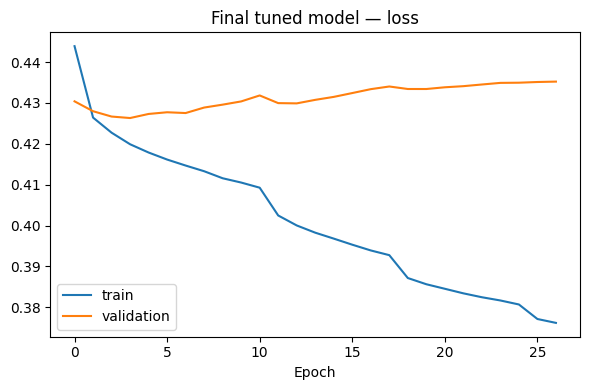

In [21]:
keras.utils.set_random_seed(SEED)
final_model = tuner.hypermodel.build(best_hp)
final_model.summary()

hist_final = final_model.fit(
    X_train_p, y_train, validation_data=(X_val_p, y_val),
    epochs=200, batch_size=BEST_BATCH, class_weight=CLASS_WEIGHT,
    callbacks=[callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=25,
                                       restore_best_weights=True),
               callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=7, min_lr=1e-5),
               callbacks.ModelCheckpoint("best_churn_model.keras", monitor="val_accuracy",
                                         mode="max", save_best_only=True)],
    verbose=0)

print("Epochs trained:", len(hist_final.history["loss"]))
plot_history({"Final tuned model": hist_final}, "loss")

## 7. Evaluation

### 7.1 Choosing the decision threshold
The default 0.5 threshold is not always the best for imbalanced data.
We pick the threshold that maximizes F1 on the **validation** set, then apply it to the test set. The test set is never used for any decision.

In [22]:
val_prob = final_model.predict(X_val_p, verbose=0).ravel()

ths = np.linspace(0.1, 0.9, 81)
accs = [accuracy_score(y_val, (val_prob >= t).astype(int)) for t in ths]
BEST_THRESHOLD = float(ths[np.argmax(accs)])
print(f"Best threshold on validation: {BEST_THRESHOLD:.3f} (Accuracy = {max(accs):.4f})")

Best threshold on validation: 0.500 (Accuracy = 0.8097)


In [23]:
def evaluate(name, y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    return {"Model": name, "Threshold": round(threshold, 3),
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred),
            "Recall": recall_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred),
            "ROC-AUC": roc_auc_score(y_true, y_prob),
            "PR-AUC": average_precision_score(y_true, y_prob)}

test_probs = {
    "Logistic Regression": lr_test_prob,
    "ANN baseline": baseline.predict(X_test_p, verbose=0).ravel(),
    "ANN regularized": regularized.predict(X_test_p, verbose=0).ravel(),
    "ANN tuned": final_model.predict(X_test_p, verbose=0).ravel(),
}

rows = [evaluate(n, y_test, p) for n, p in test_probs.items()]
rows.append(evaluate("ANN tuned (best threshold)", y_test, test_probs["ANN tuned"], BEST_THRESHOLD))
results_df = pd.DataFrame(rows).set_index("Model").round(4)
results_df

,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,,
Logistic Regression,0.5,0.7483,0.5177,0.7794,0.6222,0.8448,0.6592
ANN baseline,0.5,0.7417,0.5134,0.5445,0.5285,0.7706,0.5032
ANN regularized,0.5,0.7512,0.5215,0.7758,0.6237,0.8408,0.6456
ANN tuned,0.5,0.7985,0.6954,0.4306,0.5319,0.8436,0.6535
ANN tuned (best threshold),0.5,0.7985,0.6954,0.4306,0.5319,0.8436,0.6535


              precision    recall  f1-score   support

        Stay       0.82      0.93      0.87       776
       Churn       0.70      0.43      0.53       281

    accuracy                           0.80      1057
   macro avg       0.76      0.68      0.70      1057
weighted avg       0.79      0.80      0.78      1057



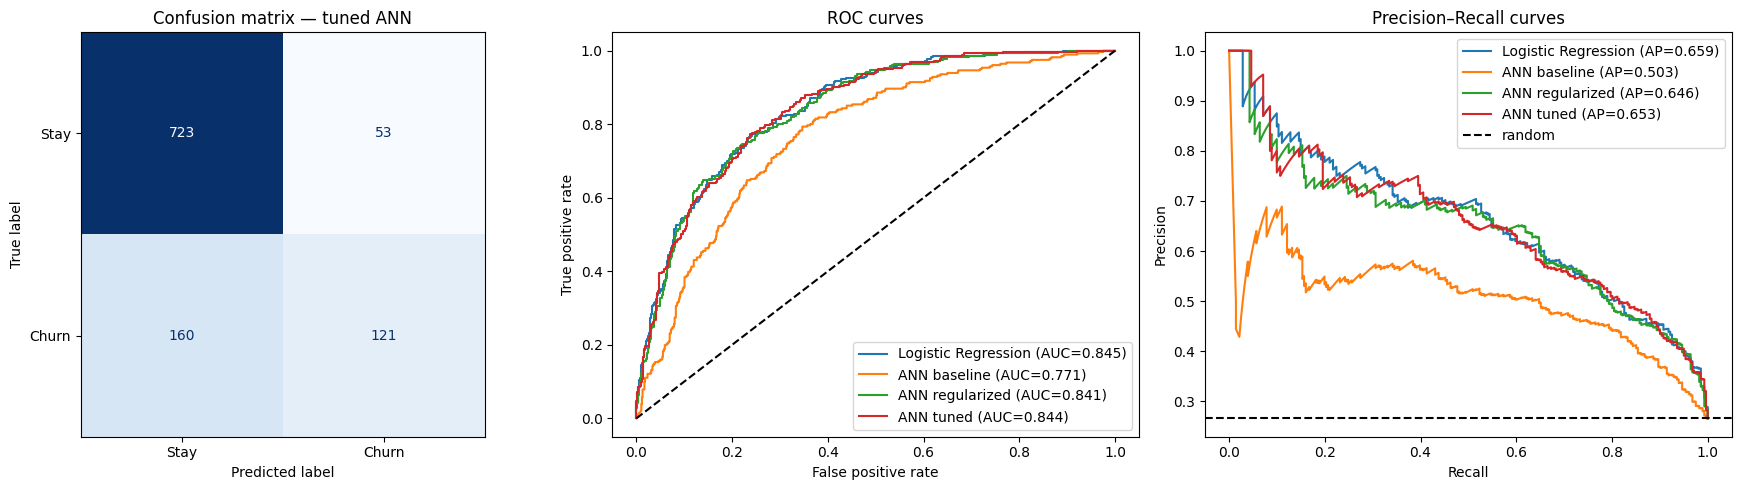

In [24]:
y_pred_final = (test_probs["ANN tuned"] >= BEST_THRESHOLD).astype(int)
print(classification_report(y_test, y_pred_final, target_names=["Stay", "Churn"]))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_final),
                       display_labels=["Stay", "Churn"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion matrix — tuned ANN")

for name, p in test_probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
axes[1].plot([0, 1], [0, 1], "k--"); axes[1].set_title("ROC curves")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate"); axes[1].legend()

for name, p in test_probs.items():
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[2].plot(rc, pr, label=f"{name} (AP={average_precision_score(y_test, p):.3f})")
axes[2].axhline(y_test.mean(), color="k", ls="--", label="random")
axes[2].set_title("Precision–Recall curves"); axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision"); axes[2].legend()

plt.tight_layout(); plt.show()

**Why these metrics:**
- **Recall (Churn):** how many leaving customers we catch. Missing a churner costs the company the most.
- **Precision:** how many flagged customers really leave. This controls wasted retention offers.
- **F1:** balance between the two.
- **ROC-AUC / PR-AUC:** ranking quality independent of the threshold. PR-AUC is more informative for imbalanced data.
- **Accuracy:** reported, but misleading here because predicting "Stay" for everyone already gives ~73%.

## 8. Model Saving & Loading

In [25]:
os.makedirs("artifacts", exist_ok=True)

final_model.save("artifacts/churn_model.keras")                 # architecture + weights + optimizer
joblib.dump(preprocessor, "artifacts/preprocessor.joblib")      # the exact same encoding/scaling
with open("artifacts/config.json", "w") as f:
    json.dump({"threshold": BEST_THRESHOLD, "num_cols": NUM_COLS, "cat_cols": CAT_COLS}, f, indent=2)

print(os.listdir("artifacts"))

['config.json', 'churn_model.keras', 'preprocessor.joblib']


In [26]:
# Load everything back as a production service would
loaded_model = keras.models.load_model("artifacts/churn_model.keras")
loaded_pre   = joblib.load("artifacts/preprocessor.joblib")
with open("artifacts/config.json") as f:
    loaded_cfg = json.load(f)

p_original = final_model.predict(X_test_p, verbose=0).ravel()
p_loaded   = loaded_model.predict(loaded_pre.transform(X_test).astype("float32"), verbose=0).ravel()
print("Loaded model gives identical predictions:", np.allclose(p_original, p_loaded, atol=1e-6))

Loaded model gives identical predictions: True


## 9. Deployment

### 9.1 Prediction function (inference on a new customer)

In [27]:
def predict_churn(customer: dict, model=loaded_model, pre=loaded_pre, cfg=loaded_cfg):
    """Takes raw customer data (same columns as the CSV, without customerID/Churn)."""
    row = pd.DataFrame([customer])
    row["TotalCharges"] = pd.to_numeric(row["TotalCharges"], errors="coerce").fillna(0)
    prob = float(model.predict(pre.transform(row).astype("float32"), verbose=0)[0, 0])
    return {"churn_probability": round(prob, 4),
            "prediction": "Churn" if prob >= cfg["threshold"] else "Stay"}

new_customer = {
    "gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No",
    "tenure": 2, "PhoneService": "Yes", "MultipleLines": "No",
    "InternetService": "Fiber optic", "OnlineSecurity": "No", "OnlineBackup": "No",
    "DeviceProtection": "No", "TechSupport": "No", "StreamingTV": "Yes",
    "StreamingMovies": "Yes", "Contract": "Month-to-month", "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check", "MonthlyCharges": 95.5, "TotalCharges": 191.0,
}
predict_churn(new_customer)

{'churn_probability': 0.7168, 'prediction': 'Churn'}

### 9.2 Web app (Streamlit)
The cell below writes `app.py`. Run it locally with:
```
pip install streamlit
streamlit run app.py
```
(`app.py` must be next to the `artifacts/` folder.)

In [28]:
%%writefile app.py
import json
import joblib
import pandas as pd
import streamlit as st
from tensorflow import keras


@st.cache_resource
def load_artifacts():
    model = keras.models.load_model("artifacts/churn_model.keras")
    pre = joblib.load("artifacts/preprocessor.joblib")
    with open("artifacts/config.json") as f:
        cfg = json.load(f)
    return model, pre, cfg


model, pre, cfg = load_artifacts()

st.set_page_config(page_title="Customer Churn Predictor", page_icon="📉")
st.title("📉 Customer Churn Prediction")
st.write("Enter the customer's details to estimate the probability that they will leave.")

YES_NO = ["No", "Yes"]
SERVICE = ["No", "Yes", "No internet service"]

c1, c2 = st.columns(2)
with c1:
    st.subheader("Customer")
    gender = st.selectbox("Gender", ["Female", "Male"])
    senior = st.selectbox("Senior citizen", YES_NO)
    partner = st.selectbox("Partner", YES_NO)
    dependents = st.selectbox("Dependents", YES_NO)
    tenure = st.slider("Tenure (months)", 0, 72, 12)

    st.subheader("Billing")
    contract = st.selectbox("Contract", ["Month-to-month", "One year", "Two year"])
    paperless = st.selectbox("Paperless billing", YES_NO)
    payment = st.selectbox("Payment method", ["Electronic check", "Mailed check",
                                              "Bank transfer (automatic)", "Credit card (automatic)"])
    monthly = st.number_input("Monthly charges", 0.0, 200.0, 70.0, step=0.5)
    total = st.number_input("Total charges", 0.0, 10000.0, float(round(monthly * tenure, 2)), step=10.0)

with c2:
    st.subheader("Services")
    phone = st.selectbox("Phone service", YES_NO, index=1)
    multiple = st.selectbox("Multiple lines", ["No", "Yes", "No phone service"])
    internet = st.selectbox("Internet service", ["DSL", "Fiber optic", "No"])
    security = st.selectbox("Online security", SERVICE)
    backup = st.selectbox("Online backup", SERVICE)
    protection = st.selectbox("Device protection", SERVICE)
    support = st.selectbox("Tech support", SERVICE)
    tv = st.selectbox("Streaming TV", SERVICE)
    movies = st.selectbox("Streaming movies", SERVICE)

if st.button("Predict", type="primary"):
    customer = pd.DataFrame([{
        "gender": gender, "SeniorCitizen": 1 if senior == "Yes" else 0,
        "Partner": partner, "Dependents": dependents, "tenure": tenure,
        "PhoneService": phone, "MultipleLines": multiple, "InternetService": internet,
        "OnlineSecurity": security, "OnlineBackup": backup, "DeviceProtection": protection,
        "TechSupport": support, "StreamingTV": tv, "StreamingMovies": movies,
        "Contract": contract, "PaperlessBilling": paperless, "PaymentMethod": payment,
        "MonthlyCharges": monthly, "TotalCharges": total,
    }])
    prob = float(model.predict(pre.transform(customer).astype("float32"), verbose=0)[0, 0])

    st.metric("Churn probability", f"{prob:.1%}")
    st.progress(min(prob, 1.0))
    if prob >= cfg["threshold"]:
        st.error("⚠️ High risk: this customer is likely to churn. Consider a retention offer.")
    else:
        st.success("✅ Low risk: this customer is likely to stay.")
    st.caption(f"Decision threshold: {cfg['threshold']:.3f}")

Writing app.py


## 10. Conclusion
- Built a full pipeline: cleaning → leak-free preprocessing → ANN → regularization → tuning → evaluation → saving → deployment.
- The baseline ANN overfits clearly. L2, Dropout, BatchNorm and Early Stopping close the train/validation gap.
- Class weights and threshold tuning raise recall on churners, which matters more to the business than raw accuracy.
- On tabular data like this, a well-tuned ANN performs close to Logistic Regression. This is a common, honest finding: a deep model's benefit grows with larger and more complex data.

**Possible improvements:** feature engineering (e.g., average charge per month, number of services), K-fold cross-validation, SHAP for explaining predictions, monitoring data drift after deployment.